# 06 — Vector retrieval from first principles

## Objective

Build a small page-level retrieval experiment, inspect its vocabulary and vectors, calculate cosine similarity directly, and rank pages for a query.

## Concept

For vectors $q$ and $d$, cosine similarity is

$$
\cos(q,d)=\frac{q\cdot d}{\lVert q\rVert_2\lVert d\rVert_2}.
$$

This notebook deliberately starts with transparent term-frequency vectors. They are not semantic embeddings: synonyms do not become close unless they share tokens. The baseline makes the retrieval mechanics inspectable before choosing a model or vector database.

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
SLIDES_PDF = PROJECT_ROOT / "data" / "documents" / "ch2.pdf"

## Implementation — extract a bounded page corpus

In [2]:
page_numbers = [9, 17, 49, 65]
with pymupdf.open(SLIDES_PDF) as document:
    page_texts = {
        page_number: document[page_number - 1].get_text("text", sort=True)
        for page_number in page_numbers
    }

text_preview = pd.DataFrame(
    {
        "page_number": page_texts.keys(),
        "characters": [len(text) for text in page_texts.values()],
        "preview": [text[:100].replace("\n", " ") for text in page_texts.values()],
    }
)
text_preview

,page_number,characters,preview
0,9,985,Why the support of the prior matters...
1,17,1183,Methods for the construction of subjective ...
2,49,1454,Exponential Famil...
3,65,363,The ML-II approach: Random Effects exam...


## Implementation — tokenize and vectorize

Tokenization lowercases alphanumeric word sequences. The vocabulary is sorted so vector dimensions are deterministic.

In [3]:
def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())


document_tokens = {page: tokenize(text) for page, text in page_texts.items()}
vocabulary = sorted({token for tokens in document_tokens.values() for token in tokens})
token_to_index = {token: index for index, token in enumerate(vocabulary)}


def vectorize(tokens):
    counts = Counter(tokens)
    vector = np.zeros(len(vocabulary), dtype=float)
    for token, count in counts.items():
        if token in token_to_index:
            vector[token_to_index[token]] = count
    return vector


document_vectors = {page: vectorize(tokens) for page, tokens in document_tokens.items()}
print("Vocabulary size:", len(vocabulary))
print("First 20 terms:", vocabulary[:20])

Vocabulary size: 229
First 20 terms: ['0', '1', '10', '11', '12', '15', '17', '1965', '1985', '1999', '1e', '2', '20', '2a', '3', '30', '40', '49', '5', '50']


## Execution — score one query

In [4]:
query = "usual conjugate pairs table"
query_vector = vectorize(tokenize(query))


def cosine_similarity(left, right):
    denominator = np.linalg.norm(left) * np.linalg.norm(right)
    return 0.0 if denominator == 0 else float(np.dot(left, right) / denominator)


score_rows = [
    {
        "page_number": page_number,
        "cosine_similarity": cosine_similarity(query_vector, page_vector),
    }
    for page_number, page_vector in document_vectors.items()
]
retrieval_scores = pd.DataFrame(score_rows).sort_values("cosine_similarity", ascending=False)
retrieval_scores

,page_number,cosine_similarity
2,49,0.044108
0,9,0.000000
1,17,0.000000
3,65,0.000000


## Inspection — ranked similarity scores

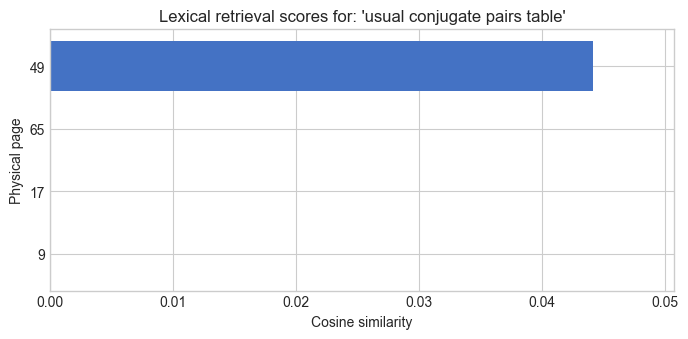

In [5]:
plot_data = retrieval_scores.sort_values("cosine_similarity")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(plot_data["page_number"].astype(str), plot_data["cosine_similarity"], color="#4472C4")
ax.set_title(f"Lexical retrieval scores for: {query!r}")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Physical page")
ax.set_xlim(0, max(0.01, retrieval_scores["cosine_similarity"].max() * 1.15))
plt.tight_layout()
plt.show()

## Interpretation

The query should rank page 49 first because it shares the distinctive terms “usual” and “conjugate.” This success does not prove semantic retrieval quality; a paraphrase with no shared vocabulary is an expected failure case.

## Validation and failure example

In [6]:
assert retrieval_scores.iloc[0]["page_number"] == 49
assert retrieval_scores["cosine_similarity"].between(0, 1).all()
assert np.isclose(cosine_similarity(query_vector, query_vector), 1.0)

paraphrase = "standard prior likelihood combinations"
paraphrase_vector = vectorize(tokenize(paraphrase))
paraphrase_scores = {
    page: cosine_similarity(paraphrase_vector, vector)
    for page, vector in document_vectors.items()
}
print("Paraphrase scores (expected lexical weakness):", paraphrase_scores)

Paraphrase scores (expected lexical weakness): {9: 0.22904699685129096, 17: 0.15944820103582016, 49: 0.09003530075820247, 65: 0.3621429841700741}


## Next step

`07_retrieval_evaluation.ipynb` defines Hit@k and demonstrates the calculation on clearly labeled mechanics-only cases. A real embedding experiment should replace this baseline only after its model, version, dimensionality, and cost are recorded.